# Argos · Notebook 02 — Análise exploratória (EDA)
Antes de treinar os modelos, queremos entender os dados: como o rendimento varia entre as regiões e ao longo dos anos, o quanto o clima parece influenciar, quais variáveis repetem a mesma informação e quantos anos de quebra existem. As decisões que tomamos para os modelos (no final deste notebook) saem desta análise.

| Etapa | Notebook |
|---|---|
| Coleta e montagem do dataset | 01_coleta_e_preparo |
| Análise exploratória (EDA) | 02_eda (este) |
| Preparação, treino e avaliação da regressão | 03_regressao |
| Preparação, treino e avaliação da classificação | 04_classificacao |
| Exportação dos modelos (.joblib) | final do 03 e do 04 |
| API REST em Flask | api/api.py |

Cada linha do dataset é um município em um ano (30 municípios, de 2010 a 2024). Nos notebooks 03 e 04, os anos de 2010 a 2019 serão o treino e os de 2020 a 2024, o teste.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 2279
df = pd.read_csv(Path("../dados/dataset_argos.csv"), encoding="utf-8")

ENTRADAS = ["chuva_total_mm", "temp_media", "temp_max_media", "dias_acima_35",
            "maior_seq_seca", "oni", "regiao_sul", "media_5a"]
REGIOES = ["NORDESTE", "SUL"]
NOME = {"NORDESTE": "Nordeste", "SUL": "Sul"}
FONTE = "Fonte: IBGE/SIDRA (PAM, tabela 1612), Open-Meteo Historical e NOAA CPC (ONI). Elaboração do grupo."

# coluna só para a EDA (não vai para o CSV nem para os modelos)
df["regiao"] = np.where(df["regiao_sul"] == 1, "SUL", "NORDESTE")

def br(valor):
    return f"{valor:,.0f}".replace(",", ".")

def rodape(fig):
    fig.text(0.01, -0.03, FONTE, fontsize=8, ha="left")

print(df.shape)
df.info()

(450, 15)
<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   cd_municipio    450 non-null    int64  
 1   nm_municipio    450 non-null    str    
 2   sg_uf           450 non-null    str    
 3   ano             450 non-null    int64  
 4   chuva_total_mm  450 non-null    float64
 5   temp_media      450 non-null    float64
 6   temp_max_media  450 non-null    float64
 7   dias_acima_35   450 non-null    int64  
 8   maior_seq_seca  450 non-null    int64  
 9   oni             450 non-null    float64
 10  regiao_sul      450 non-null    int64  
 11  media_5a        450 non-null    float64
 12  rend_kg_ha      450 non-null    float64
 13  quebra          450 non-null    int64  
 14  regiao          450 non-null    str    
dtypes: float64(6), int64(6), str(3)
memory usage: 52.9 KB


In [2]:
print("Valores ausentes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() > 0 else "nenhum")
df[ENTRADAS + ["rend_kg_ha", "quebra"]].describe().round(1).T

Valores ausentes por coluna:
nenhum


,count,mean,std,min,25%,50%,75%,max
chuva_total_mm,450.0,1125.3,601.0,166.6,600.6,1031.8,1646.7,2653.8
temp_media,450.0,23.1,2.6,16.0,21.6,23.3,24.8,29.1
temp_max_media,450.0,28.3,2.8,21.0,26.7,28.6,30.2,34.4
dias_acima_35,450.0,15.2,25.1,0.0,0.0,5.0,18.8,153.0
maior_seq_seca,450.0,36.4,38.4,7.0,17.0,23.0,34.0,202.0
oni,450.0,0.1,0.6,-0.8,-0.4,-0.1,0.5,1.5
regiao_sul,450.0,0.5,0.5,0.0,0.0,0.5,1.0,1.0
media_5a,450.0,3484.1,2298.4,103.6,1029.2,4194.7,5276.2,9076.0
rend_kg_ha,450.0,3694.9,2568.6,12.0,1050.0,4012.0,5708.8,9600.0
quebra,450.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0


**Interpretação.** São 450 linhas e nenhum valor ausente, porque os ausentes do IBGE já foram tratados no notebook 01: os municípios com algum ano faltando saíram, e os anos de 2005 a 2009 saíram por não terem histórico de 5 anos. As variáveis têm escalas muito diferentes: a chuva vai de 166,6 a 2.653,8 mm por ano, `dias_acima_35` vai de 0 a 153 e o rendimento vai de 12 a 9.600 kg/ha. Isso importa para o KNN e para a Regressão Logística, que são sensíveis à escala, e por isso vamos padronizar os dados com o `StandardScaler` antes de treinar.

## 1. Distribuição do rendimento por região

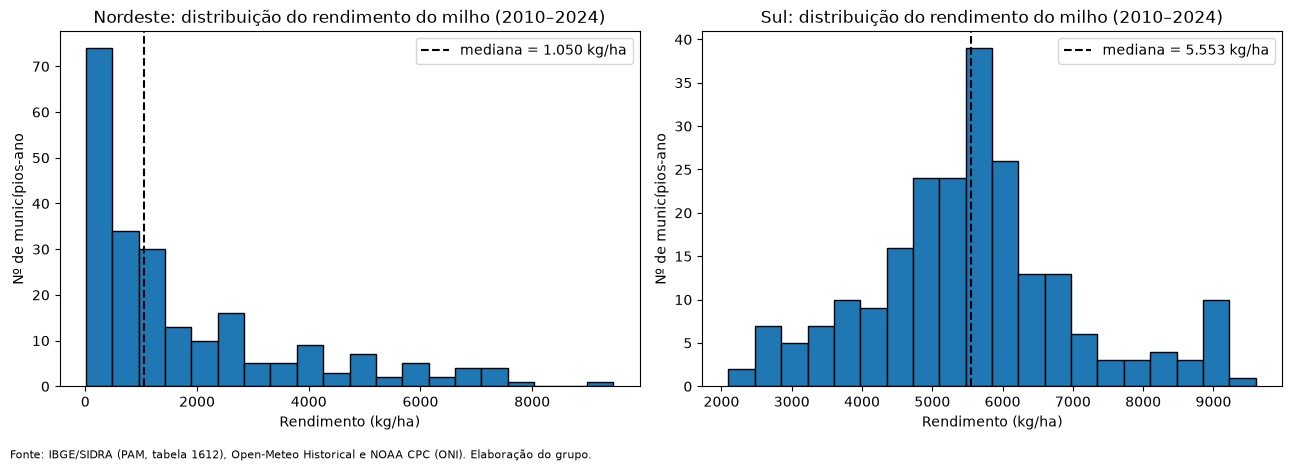

,count,mean,std,min,25%,50%,75%,max
regiao,,,,,,,,
NORDESTE,225.0,1822.0,1994.0,12.0,336.0,1050.0,2600.0,9449.0
SUL,225.0,5568.0,1484.0,2100.0,4730.0,5553.0,6218.0,9600.0


In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for eixo, regiao in zip(eixos, REGIOES):
    valores = df.loc[df["regiao"] == regiao, "rend_kg_ha"]
    eixo.hist(valores, bins=20, edgecolor="black")
    eixo.axvline(valores.median(), color="black", linestyle="--",
                 label=f"mediana = {br(valores.median())} kg/ha")
    eixo.set_title(f"{NOME[regiao]}: distribuição do rendimento do milho (2010–2024)")
    eixo.set_xlabel("Rendimento (kg/ha)")
    eixo.set_ylabel("Nº de municípios-ano")
    eixo.legend()
rodape(fig)
plt.tight_layout()
plt.show()

df.groupby("regiao")["rend_kg_ha"].describe().round(0)

**Interpretação.** As duas regiões são muito diferentes. No Nordeste, a mediana é de 1.050 kg/ha e metade dos anos fica entre 336 e 2.600 kg/ha, mas existem alguns valores bem altos (até 9.449 kg/ha), de municípios com lavoura mais tecnificada, como Paripiranga, Adustina e Serra do Ramalho. No Sul, a mediana é de 5.553 kg/ha e os valores são mais concentrados (metade dos anos entre 4.730 e 6.218 kg/ha). Por isso faz mais sentido comparar cada município com o próprio histórico (`media_5a`) do que comparar municípios entre si, e a região precisa entrar no modelo.

## 2. Rendimento ao longo dos anos

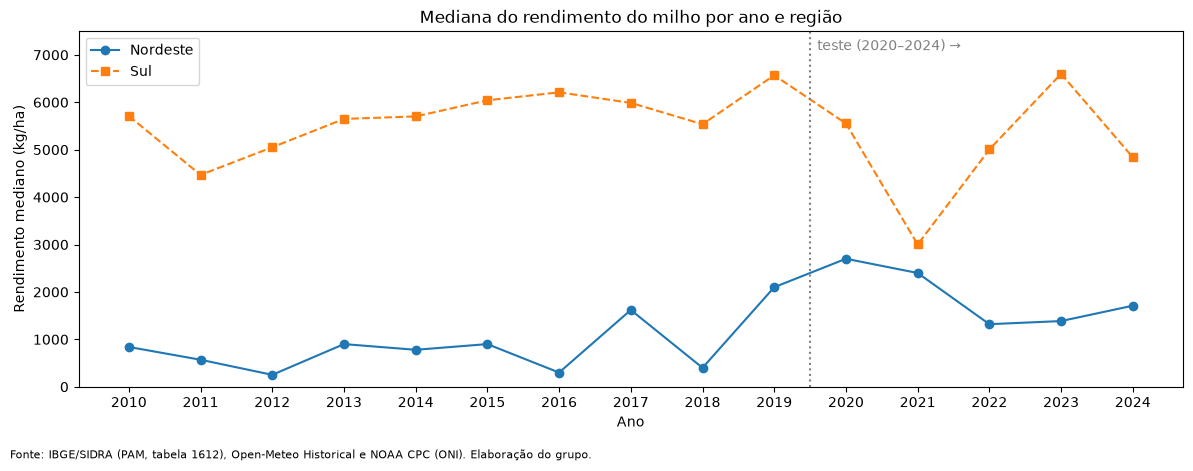

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
regiao,,,,,,,,,,,,,,,
NORDESTE,840.0,570.0,252.0,900.0,780.0,900.0,300.0,1620.0,400.0,2100.0,2700.0,2400.0,1320.0,1386.0,1710.0
SUL,5711.0,4469.0,5051.0,5649.0,5702.0,6042.0,6210.0,5987.0,5537.0,6570.0,5553.0,3001.0,5005.0,6600.0,4840.0


In [4]:
mediana_ano = df.groupby(["ano", "regiao"])["rend_kg_ha"].median().unstack()

fig, eixo = plt.subplots(figsize=(12, 4.5))
eixo.plot(mediana_ano.index, mediana_ano["NORDESTE"], marker="o", linestyle="-", label="Nordeste")
eixo.plot(mediana_ano.index, mediana_ano["SUL"], marker="s", linestyle="--", label="Sul")
eixo.set_ylim(0, 7500)
eixo.axvline(2019.5, color="gray", linestyle=":")
eixo.text(2019.6, 7100, "teste (2020–2024) →", color="gray")
eixo.set_title("Mediana do rendimento do milho por ano e região")
eixo.set_xlabel("Ano")
eixo.set_ylabel("Rendimento mediano (kg/ha)")
eixo.set_xticks(mediana_ano.index)
eixo.legend()
rodape(fig)
plt.tight_layout()
plt.show()

mediana_ano.round(0).T

**Interpretação.** No Sul, a mediana fica quase sempre entre 5.000 e 6.600 kg/ha, e os anos ruins aparecem como quedas no gráfico: 2011 (4.469), 2021 (3.001, o pior ano) e 2024 (4.840). No Nordeste, o rendimento é baixo até 2018, com os piores anos em 2012 (252 kg/ha) e 2016 (300 kg/ha), e sobe a partir de 2019 (2.100 em 2019 e 2.700 em 2020). Isso tem duas consequências. Primeiro, o período de teste começa num patamar mais alto que o de treino no Nordeste, então o modelo precisa da média dos anos recentes (`media_5a`) para acompanhar essa mudança. Segundo, confirma que devemos separar treino e teste por ano, e não por sorteio, porque um sorteio misturaria anos de patamares diferentes.

## 3. Clima × rendimento (dentro de cada região)

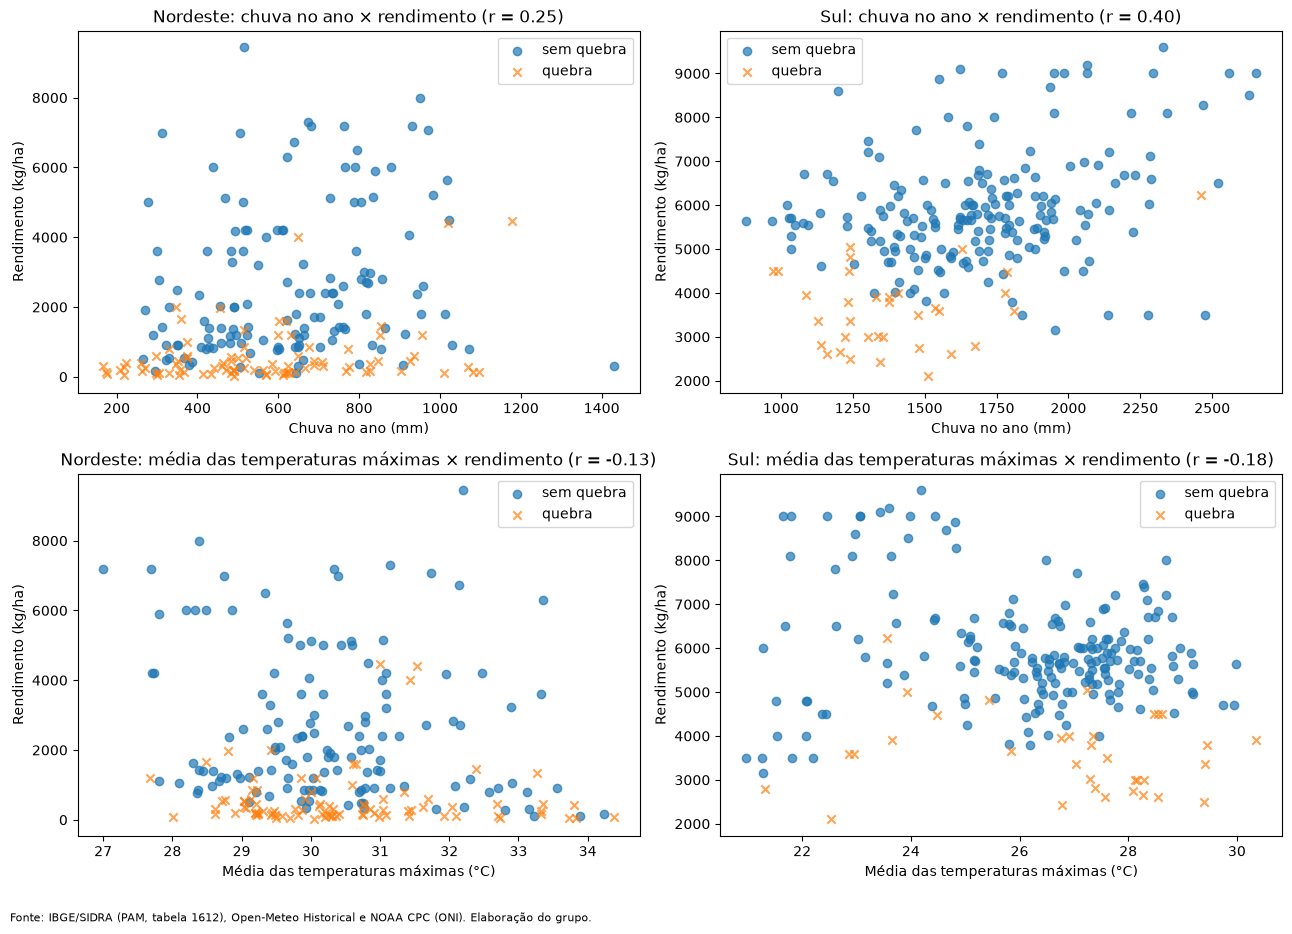

Correlação com o rendimento, juntando as regiões:
chuva_total_mm    0.74
temp_max_media   -0.62
dtype: float64


In [5]:
VARIAVEIS_CLIMA = [("chuva_total_mm", "Chuva no ano (mm)"), ("temp_max_media", "Média das temperaturas máximas (°C)")]

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for coluna, regiao in enumerate(REGIOES):
    parte = df[df["regiao"] == regiao]
    for linha, (variavel, rotulo) in enumerate(VARIAVEIS_CLIMA):
        eixo = eixos[linha, coluna]
        for valor, marcador, nome in [(0, "o", "sem quebra"), (1, "x", "quebra")]:
            pontos = parte[parte["quebra"] == valor]
            eixo.scatter(pontos[variavel], pontos["rend_kg_ha"], marker=marcador, alpha=0.7, label=nome)
        r = parte[variavel].corr(parte["rend_kg_ha"])
        eixo.set_title(f"{NOME[regiao]}: {rotulo.split(' (')[0].lower()} × rendimento (r = {r:.2f})")
        eixo.set_xlabel(rotulo)
        eixo.set_ylabel("Rendimento (kg/ha)")
        eixo.legend()
rodape(fig)
plt.tight_layout()
plt.show()

print("Correlação com o rendimento, juntando as regiões:")
print(df[["chuva_total_mm", "temp_max_media"]].corrwith(df["rend_kg_ha"]).round(2))

**Interpretação.** Juntando as duas regiões, a correlação entre chuva e rendimento é alta (r = 0,74). Mas isso acontece principalmente porque o Sul chove mais e também colhe mais: a chuva tem correlação de 0,87 com a variável `regiao_sul` (mapa da próxima seção). Olhando cada região separadamente, a relação é fraca no Nordeste (r = 0,25 com a chuva e −0,13 com a temperatura máxima) e moderada no Sul (r = 0,40 e −0,18). No Nordeste, os anos de quebra (marcados com x) aparecem em quase todas as faixas de chuva. Uma explicação provável é que a chuva somada no ano inteiro é uma medida grosseira, já que, para o milho, o que mais importa é a chuva na época do plantio e da floração. Por isso esperamos que o modelo ganhe pouco do baseline.

## 4. Correlação entre as variáveis

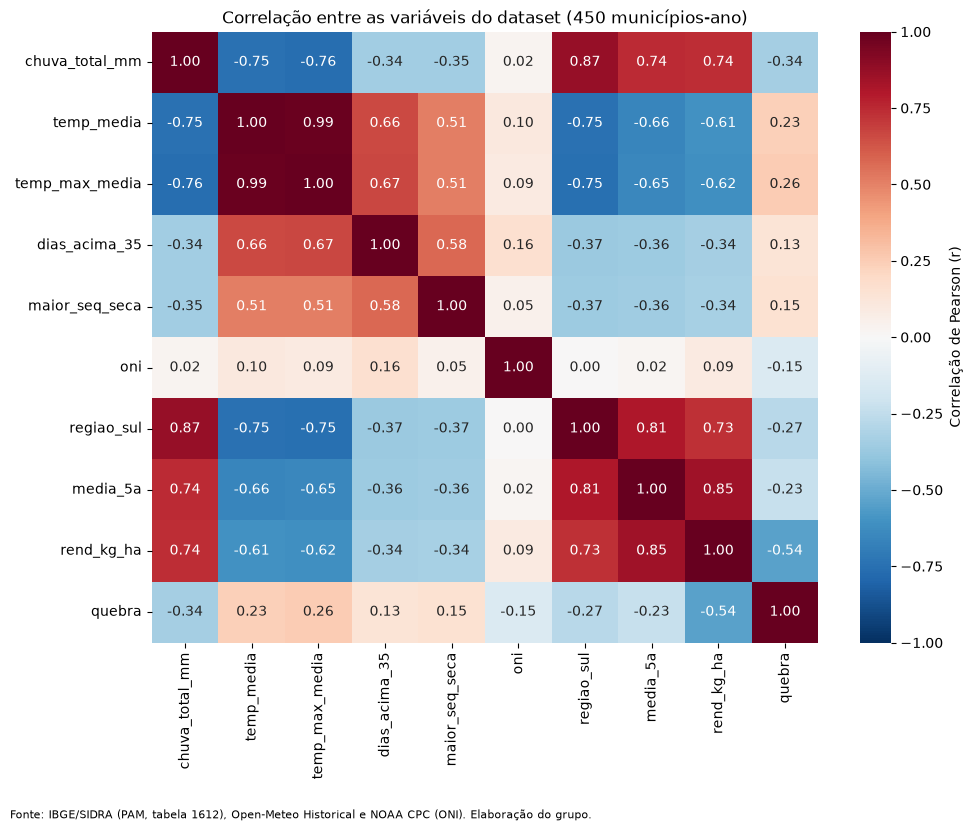

,variavel_1,variavel_2,r
7,temp_media,temp_max_media,0.99
5,chuva_total_mm,regiao_sul,0.87
27,regiao_sul,media_5a,0.81
1,chuva_total_mm,temp_max_media,-0.76
11,temp_media,regiao_sul,-0.75


In [6]:
correlacao = df[ENTRADAS + ["rend_kg_ha", "quebra"]].corr()

fig, eixo = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=eixo,
            cbar_kws={"label": "Correlação de Pearson (r)"})
eixo.set_title("Correlação entre as variáveis do dataset (450 municípios-ano)")
rodape(fig)
plt.tight_layout()
plt.show()

pares = []
for i, a in enumerate(ENTRADAS):
    for b in ENTRADAS[i + 1:]:
        pares.append((a, b, round(correlacao.loc[a, b], 2)))
pares = pd.DataFrame(pares, columns=["variavel_1", "variavel_2", "r"])
pares.reindex(pares["r"].abs().sort_values(ascending=False).index).head(5)

**Interpretação.**
- `temp_media` e `temp_max_media` têm correlação de 0,99, ou seja, carregam praticamente a mesma informação. Quando duas variáveis quase iguais entram juntas numa regressão, o modelo não consegue separar o efeito de cada uma, e os coeficientes ficam instáveis (colinearidade). Por isso decidimos usar só a `temp_max_media`, que tem correlação um pouco maior com a quebra (0,26 contra 0,23).
- A chuva tem correlação de 0,87 com a região, e a `media_5a` tem 0,81. Mantemos as três, porque cada uma traz alguma informação própria, mas sabendo que os coeficientes delas precisam ser lidos em conjunto.
- A variável mais ligada ao rendimento é a `media_5a` (r = 0,85). Por isso o baseline da regressão será "o rendimento deste ano é igual à média dos 5 anos anteriores".
- Com a quebra, as correlações são fracas: −0,34 com a chuva, 0,26 com a temperatura máxima e −0,15 com o ONI. A correlação de −0,54 com o rendimento é esperada, porque a quebra é calculada a partir dele; o rendimento não é usado como entrada do classificador.

## 5. Quantas quebras existem, onde e quando

Quebra no total: 27.3% (123 de 450 linhas)
                           quebras  linhas  proporcao
periodo          regiao                              
teste 2020-2024  NORDESTE       26      75      0.347
                 SUL            26      75      0.347
treino 2010-2019 NORDESTE       63     150      0.420
                 SUL             8     150      0.053


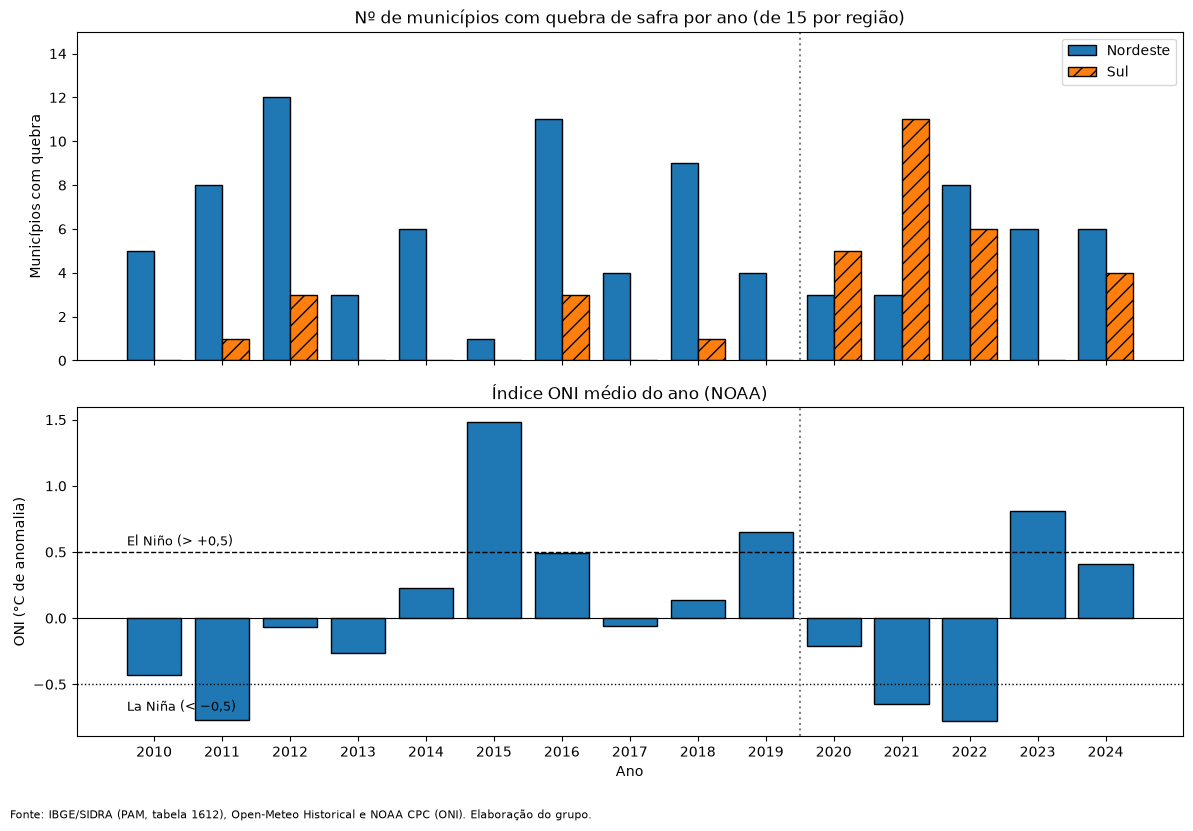

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
regiao,,,,,,,,,,,,,,,
NORDESTE,5,8,12,3,6,1,11,4,9,4,3,3,8,6,6
SUL,0,1,3,0,0,0,3,0,1,0,5,11,6,0,4


In [7]:
periodo = np.where(df["ano"] <= 2019, "treino 2010-2019", "teste 2020-2024")
tabela = df.assign(periodo=periodo).groupby(["periodo", "regiao"])["quebra"].agg(quebras="sum", linhas="count", proporcao="mean")
print(f"Quebra no total: {df['quebra'].mean():.1%} ({df['quebra'].sum()} de {len(df)} linhas)")
print(tabela.round(3))

por_ano = df.groupby(["ano", "regiao"])["quebra"].sum().unstack()
oni_ano = df.groupby("ano")["oni"].first()

fig, (eixo1, eixo2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
largura = 0.4
eixo1.bar(por_ano.index - largura / 2, por_ano["NORDESTE"], width=largura, edgecolor="black", label="Nordeste")
eixo1.bar(por_ano.index + largura / 2, por_ano["SUL"], width=largura, edgecolor="black", hatch="//", label="Sul")
eixo1.set_ylim(0, 15)
eixo1.axvline(2019.5, color="gray", linestyle=":")
eixo1.set_title("Nº de municípios com quebra de safra por ano (de 15 por região)")
eixo1.set_ylabel("Municípios com quebra")
eixo1.legend()

eixo2.bar(oni_ano.index, oni_ano, edgecolor="black")
eixo2.axhline(0.5, color="black", linestyle="--", linewidth=1)
eixo2.axhline(-0.5, color="black", linestyle=":", linewidth=1)
eixo2.axhline(0, color="black", linewidth=0.8)
eixo2.text(2009.6, 0.55, "El Niño (> +0,5)", fontsize=9)
eixo2.text(2009.6, -0.7, "La Niña (< −0,5)", fontsize=9)
eixo2.axvline(2019.5, color="gray", linestyle=":")
eixo2.set_title("Índice ONI médio do ano (NOAA)")
eixo2.set_xlabel("Ano")
eixo2.set_ylabel("ONI (°C de anomalia)")
eixo2.set_xticks(oni_ano.index)
rodape(fig)
plt.tight_layout()
plt.show()

por_ano.T

**Interpretação.**
- 27,3% das linhas são quebra (123 de 450). As classes estão desbalanceadas, mas a quebra fica bem acima dos 10% que o grupo tinha definido como limite para rever a regra. Para lidar com o desbalanceamento, a Regressão Logística vai usar `class_weight="balanced"`, e vamos escolher o modelo pelo recall da classe quebra.
- No Nordeste, as quebras se concentram em 2012 (12 dos 15 municípios) e 2016 (11 de 15), anos de seca forte no semiárido.
- No Sul, quase não há quebra nos anos de treino (8 de 150 linhas, 5,3%). Das 34 quebras do Sul, 22 aconteceram entre 2020 e 2022, anos de La Niña (ONI de −0,21, −0,65 e −0,78). O pior ano foi 2021, com 11 dos 15 municípios.
- Para o modelo, isso significa que no teste o Sul tem 34,7% de quebra, contra 5,3% no treino. Ele vai ser avaliado justamente no tipo de ano que quase não viu.

## 6. Outliers (regra do IQR)

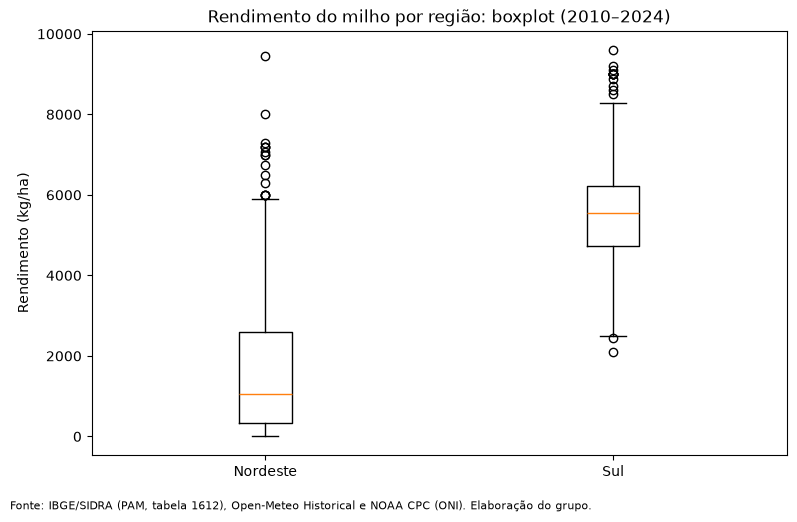


Nordeste: limites 0 a 5.996 kg/ha | 16 outliers
nm_municipio      quebra
Adustina          0         3
Paripiranga       0         9
Serra do Ramalho  0         4

Sul: limites 2.498 a 8.450 kg/ha | 16 outliers
nm_municipio     quebra
Bento Gonçalves  1         1
Chapecó          0         8
Passo Fundo      0         6
Toledo           1         1


In [8]:
dados_box = []
for regiao in REGIOES:
    dados_box.append(df.loc[df["regiao"] == regiao, "rend_kg_ha"])

fig, eixo = plt.subplots(figsize=(8, 5))
eixo.boxplot(dados_box, tick_labels=["Nordeste", "Sul"])
eixo.set_title("Rendimento do milho por região: boxplot (2010–2024)")
eixo.set_ylabel("Rendimento (kg/ha)")
rodape(fig)
plt.tight_layout()
plt.show()

for regiao in REGIOES:
    parte = df[df["regiao"] == regiao]
    q1, q3 = parte["rend_kg_ha"].quantile([0.25, 0.75])
    iqr = q3 - q1
    fora = parte[(parte["rend_kg_ha"] < q1 - 1.5 * iqr) | (parte["rend_kg_ha"] > q3 + 1.5 * iqr)]
    print(f"\n{NOME[regiao]}: limites {br(max(q1 - 1.5 * iqr, 0))} a {br(q3 + 1.5 * iqr)} kg/ha | {len(fora)} outliers")
    print(fora.groupby(["nm_municipio", "quebra"]).size().rename("anos").to_string())

**Interpretação.** Pela regra do IQR (valores abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR), existem 16 outliers no Nordeste e 16 no Sul. No Nordeste, todos são rendimentos altos de três municípios mais tecnificados (Paripiranga, Adustina e Serra do Ramalho), e nenhum é ano de quebra. No Sul, 14 são altos (Chapecó e Passo Fundo, que chegam perto de 9.000 kg/ha) e 2 são baixos: Toledo em 2021 e Bento Gonçalves em 2012, que são justamente anos de quebra. Decidimos não remover nenhum. São dados reais do IBGE, e os valores baixos são exatamente o que queremos prever; tirá-los faria o modelo aprender que quebra quase não acontece.

## 7. Como o clima muda nos anos de quebra

In [9]:
df.groupby(["regiao", "quebra"])[["chuva_total_mm", "temp_max_media", "dias_acima_35", "maior_seq_seca", "oni"]].mean().round(1)

chuva_total_mm  temp_max_media  dias_acima_35  \
regiao   quebra                                                  
NORDESTE 0                630.7            30.3           24.3   
         1                560.9            30.5           25.0   
SUL      0               1692.4            26.1            5.2   
         1               1395.7            26.8            9.2   

                 maior_seq_seca  oni  
regiao   quebra                       
NORDESTE 0                 47.3  0.1  
         1                 55.1  0.0  
SUL      0                 22.4  0.1  
         1                 22.3 -0.3

**Interpretação.** No Nordeste, os anos de quebra tiveram em média 561 mm de chuva, contra 631 mm nos anos sem quebra, e a maior sequência seca foi de 55 dias, contra 47. Existe diferença, mas ela é pequena perto da variação entre os municípios. No Sul, a diferença é mais clara: 1.396 mm contra 1.692 mm de chuva, ONI de −0,3 contra +0,1 (La Niña) e 9,2 contra 5,2 dias acima de 35 °C. Esperamos, então, que o classificador tenha mais facilidade para separar os anos no Sul do que no Nordeste.

## 8. Principais conclusões da EDA
1. **A região pesa muito.** Na mediana, o Sul colhe cerca de 5 vezes mais que o Nordeste (5.553 contra 1.050 kg/ha), e a região está muito ligada à chuva (r = 0,87). A melhor referência para cada município é o próprio histórico: a `media_5a` tem correlação de 0,85 com o rendimento.
2. **O clima do ano explica pouco no Nordeste e um pouco mais no Sul.** Dentro de cada região, a correlação entre chuva e rendimento é de 0,25 no Nordeste e de 0,40 no Sul. No Sul, as quebras de 2020 a 2022 coincidem com La Niña.
3. **O período de teste é mais difícil que o de treino.** No Sul, a quebra passa de 5,3% no treino para 34,7% no teste, e no Nordeste o rendimento sobe de patamar a partir de 2019. Um resultado modesto no teste é esperado e vai ser interpretado com esse contexto.

## 9. Decisões para os modelos
| Decisão | Por quê |
|---|---|
| Usar 7 das 8 variáveis: `chuva_total_mm`, `temp_max_media`, `dias_acima_35`, `maior_seq_seca`, `oni`, `regiao_sul` e `media_5a` | A `temp_media` sai por ser quase igual à `temp_max_media` (r = 0,99). A API continua recebendo os 8 campos combinados com o front e ignora o que o modelo não usa. |
| Treino com 2010 a 2019 e teste com 2020 a 2024 | O Argos vai usar o modelo para prever anos futuros a partir de anos passados. Um sorteio colocaria anos como 2022 no treino e 2015 no teste. |
| Padronizar com o `StandardScaler`, ajustado só no treino | As variáveis têm escalas muito diferentes (de 0 a 1 na região até 9.000 na `media_5a`). O KNN usa distância, e a padronização também deixa os coeficientes da Logística comparáveis. |
| Na regressão, comparar com o baseline "rendimento = `media_5a`" | É a variável mais correlacionada com o rendimento (0,85). O modelo só vale a pena se fizer melhor que essa regra simples. |
| Na classificação, usar `class_weight="balanced"` e escolher pelo recall da quebra | 27,3% das linhas são quebra. Para o produtor, não ser avisado de uma quebra é pior do que receber um alarme a mais. |
| Não remover outliers | São dados reais, e os valores baixos são as próprias quebras. |

## 10. Linhas reais para a demonstração da API
Para a demonstração no Insomnia e no card do front, escolhemos duas linhas reais do período de teste, usando um critério fixo e sem olhar o que o modelo prevê:
- **ano seco no semiárido:** entre os anos de quebra do Nordeste de 2020 a 2024, o que teve menos chuva;
- **ano normal no Sul:** entre os anos sem quebra do Sul de 2020 a 2024, o que teve a chuva mais próxima da mediana do Sul nesse período.

Petrolina, que é o exemplo usado no resto do projeto, não está no dataset (ver notebook 01).

In [10]:
INTEIRAS = ["dias_acima_35", "maior_seq_seca", "regiao_sul"]

def linha_para_json(linha):
    entrada = {}
    for coluna in ENTRADAS:
        entrada[coluna] = int(linha[coluna]) if coluna in INTEIRAS else float(linha[coluna])
    return json.dumps(entrada, ensure_ascii=False)

teste = df[df["ano"] >= 2020]

nordeste_quebra = teste[(teste["regiao_sul"] == 0) & (teste["quebra"] == 1)]
seco = nordeste_quebra.loc[nordeste_quebra["chuva_total_mm"].idxmin()]

sul_teste = teste[teste["regiao_sul"] == 1]
mediana_sul = sul_teste["chuva_total_mm"].median()
sul_normal = sul_teste[sul_teste["quebra"] == 0]
normal = sul_normal.loc[(sul_normal["chuva_total_mm"] - mediana_sul).abs().idxmin()]

for titulo, linha in [("Ano seco no semiárido", seco), ("Ano normal no Sul", normal)]:
    print(f"{titulo}: {linha['nm_municipio']} ({linha['sg_uf']}), {linha['ano']} | "
          f"colheu {br(linha['rend_kg_ha'])} kg/ha, média dos 5 anos = {br(linha['media_5a'])} | quebra = {linha['quebra']}")
    print(linha_para_json(linha), "\n")

Ano seco no semiárido: Araci (BA), 2023 | colheu 103 kg/ha, média dos 5 anos = 670 | quebra = 1
{"chuva_total_mm": 482.2, "temp_media": 25.67, "temp_max_media": 31.42, "dias_acima_35": 48, "maior_seq_seca": 26, "oni": 0.81, "regiao_sul": 0, "media_5a": 669.6} 

Ano normal no Sul: Chapecó (SC), 2020 | colheu 8.880 kg/ha, média dos 5 anos = 9.000 | quebra = 0
{"chuva_total_mm": 1550.5, "temp_media": 19.47, "temp_max_media": 24.82, "dias_acima_35": 1, "maior_seq_seca": 18, "oni": -0.21, "regiao_sul": 1, "media_5a": 9000.0} 



**Interpretação.** O ano seco escolhido foi Araci (BA) em 2023, um ano de El Niño (ONI = 0,81) com 482,2 mm de chuva: o município colheu 103 kg/ha, quando a média dos 5 anos anteriores era de 670 kg/ha. O ano normal foi Chapecó (SC) em 2020, com 1.550,5 mm de chuva (exatamente a mediana do Sul no teste): colheu 8.880 kg/ha, contra uma média de 9.000. Chapecó também está no banco de dados do Argos. Os dois JSON impressos acima são os que usamos no Insomnia, e o de Araci vai no card da tela Hoje.